<a href="https://colab.research.google.com/github/vaibhavzipare/ML-PRACTICALS/blob/main/Practical_10_Deep_Neural_Network_DNN_for_Digit_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 10: Deep Neural Network (DNN) for Digit Classification

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Basic_DNN_Digit_Classification.ipynb`

**A. Aim:** To build a simple 2-3 layer Deep Neural Network using Keras for handwritten digit classification and visualize model layers, activations and loss (MNIST).

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install tensorflow numpy matplotlib jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* tensorflow (Keras), numpy, matplotlib (internet needed the first time to download MNIST)

# Experiment: Deep Neural Network (DNN) for Digit Classification


**Aim:** To build a simple 2–3 layer Deep Neural Network using Keras for handwritten digit classification and visualize model layers, activations and loss.

**Dataset:** MNIST handwritten digits (0–9), with images of size 28 × 28 pixels.

Run the cells one by one in Google Colab.

## 1. Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten

## 2. Load and display the digit dataset

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


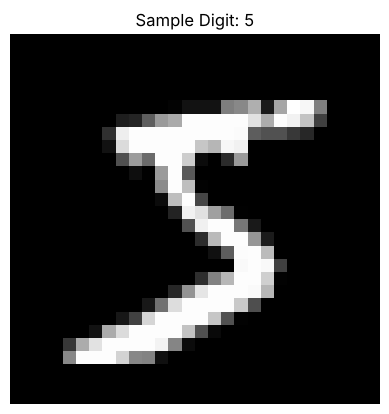

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

plt.imshow(X_train[0], cmap="gray")
plt.title("Sample Digit: " + str(y_train[0]))
plt.axis("off")
plt.show()

## 3. Normalize the images

In [ ]:
# Convert pixel values from 0-255 to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Image size:", X_train[0].shape)

Image size: (28, 28)


## 4. Build a simple DNN model

- Flatten: converts the 28 × 28 image into a one-dimensional array.
- Hidden Dense layer: 128 neurons with ReLU activation.
- Output Dense layer: 10 neurons (digits 0–9) with Softmax activation.

In [ ]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

# Display the model layers
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Compile and train the model

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9222 - loss: 0.2734 - val_accuracy: 0.9663 - val_loss: 0.1275
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9643 - loss: 0.1200 - val_accuracy: 0.9710 - val_loss: 0.1026
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9754 - loss: 0.0825 - val_accuracy: 0.9762 - val_loss: 0.0818
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9816 - loss: 0.0609 - val_accuracy: 0.9777 - val_loss: 0.0815
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9854 - loss: 0.0472 - val_accuracy: 0.9793 - val_loss: 0.0760


## 6. Visualize training and validation loss

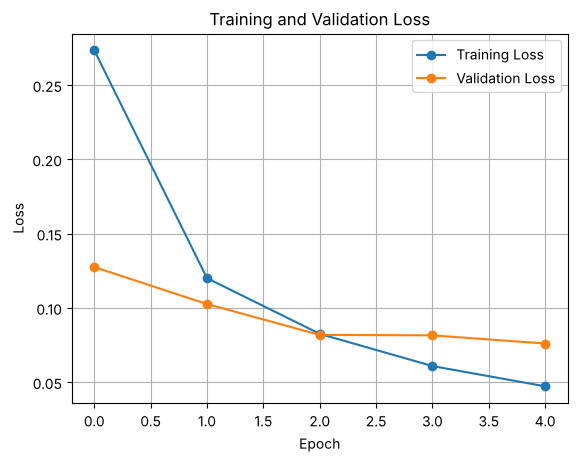

In [ ]:
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7. Visualize training and validation accuracy

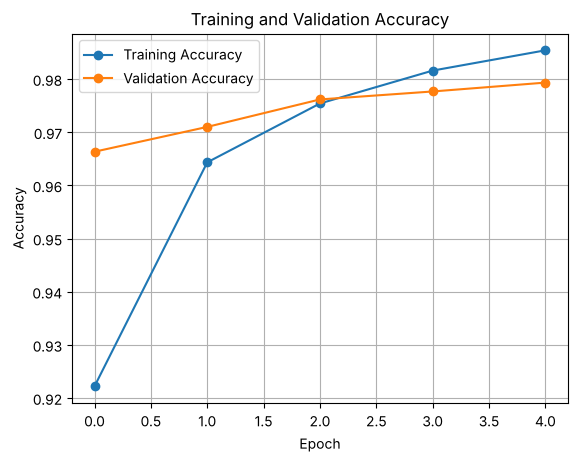

In [ ]:
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 8. Visualize hidden-layer activations

An activation is the output produced by a layer for a given input image. We display the first 16 values from the hidden Dense layer.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


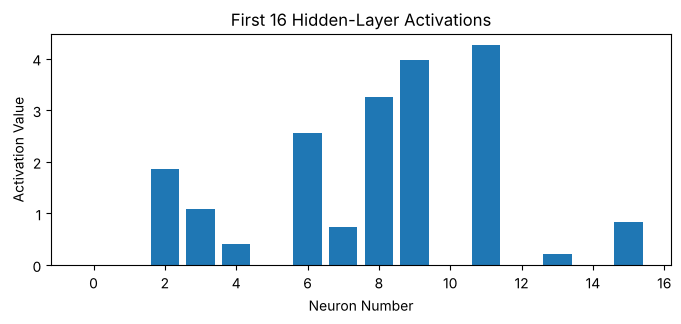

In [ ]:
activation_model = Model(
    inputs=model.inputs,
    outputs=model.layers[1].output
)

activations = activation_model.predict(X_test[0:1])

plt.figure(figsize=(8, 3))
plt.bar(range(16), activations[0][:16])
plt.xlabel("Neuron Number")
plt.ylabel("Activation Value")
plt.title("First 16 Hidden-Layer Activations")
plt.show()

## 9. Predict a digit

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


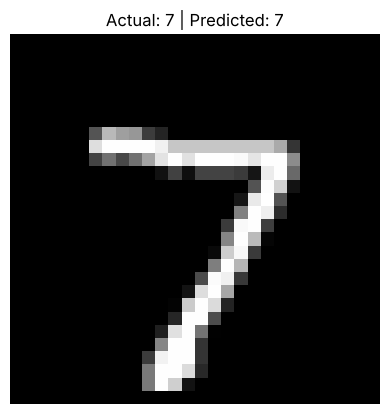

Actual digit: 7
Predicted digit: 7


In [ ]:
prediction = model.predict(X_test[0:1])
predicted_digit = np.argmax(prediction)

plt.imshow(X_test[0], cmap="gray")
plt.title("Actual: " + str(y_test[0]) +
          " | Predicted: " + str(predicted_digit))
plt.axis("off")
plt.show()

print("Actual digit:", y_test[0])
print("Predicted digit:", predicted_digit)

## 10. Evaluate the model

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9756 - loss: 0.0824
Test Loss: 0.0824
Test Accuracy: 97.56 %


## Observations
1. MNIST contains grayscale images of handwritten digits from 0 to 9.
2. The Flatten layer converts each image into a one-dimensional input.
3. The hidden Dense layer learns patterns from the digit images.
4. The output layer has 10 neurons, one for each digit.
5. The loss graph shows how prediction error changes during training.
6. The activation graph displays the output values of selected hidden-layer neurons.
7. Test accuracy indicates how well the model classifies unseen images.

## Result
A simple Deep Neural Network was built using Keras for handwritten digit classification. Model layers, hidden-layer activations, training loss and accuracy were visualized, and the model was evaluated using test data.

### D. Input Experiment 1 - Smaller hidden layer (128 -> 16 neurons)

**Changed input:** `Dense(128, ...)` -> `Dense(16, ...)` in Step 4

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #4 (section *4. Build a simple DNN model*).

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


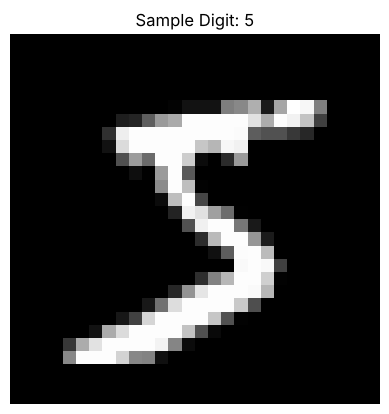

Image size: (28, 28)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │        12,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,730 (49.73 KB)

 Trainable params: 12,730 (49.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8701 - loss: 0.4660 - val_accuracy: 0.9363 - val_loss: 0.2243
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9265 - loss: 0.2539 - val_accuracy: 0.9480 - val_loss: 0.1830
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9364 - loss: 0.2159 - val_accuracy: 0.9517 - val_loss: 0.1672
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9424 - loss: 0.1943 - val_accuracy: 0.9563 - val_loss: 0.1593
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9471 - loss: 0.1785 - val_accuracy: 0.9573 - val_loss: 0.1531
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9460 - loss: 0.1819
Test Loss: 0.1819
Test Accuracy: 94.6 %


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten

tf.keras.utils.set_random_seed(42)   # ADDED line (the original has no seed, so results differ slightly on every run)

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

plt.imshow(X_train[0], cmap="gray")
plt.title("Sample Digit: " + str(y_train[0]))
plt.axis("off")
plt.show()

# Convert pixel values from 0-255 to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Image size:", X_train[0].shape)

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(16, activation="relu"),  # <-- CHANGED (original: Dense(128, activation="relu"),)
    Dense(10, activation="softmax")
])

# Display the model layers
model.summary()

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

**Actual output explained**

**What changed:** the hidden layer has 16 neurons instead of 128. The summary shows **12,730** parameters (was 101,770); test accuracy **94.6 %**, loss 0.1819 (the original Colab run gave 97.72 %; a seeded run of the original 128-neuron model on my machine gave 97.40 %).

**Why:** fewer neurons = less capacity to learn digit patterns, so accuracy drops by about 3 points, but the model is 8x smaller.